In [24]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
sns.set_theme(style="whitegrid")

DATA_FILE = "loan_default.csv"  # Change to the exact name of your CSV or Excel file
path = Path(DATA_FILE)
if not path.exists():
    raise FileNotFoundError(f"Put the dataset beside this notebook and update DATA_FILE. Missing: {path.resolve()}")
if path.suffix.lower() in {".xlsx", ".xls"}:
    df = pd.read_excel(path)
elif path.suffix.lower() == ".csv":
    df = pd.read_csv(path)
else:
    raise ValueError("Use a .csv, .xlsx, or .xls dataset.")

print("Shape (rows, columns):", df.shape)
display(df.dtypes.rename("data type").to_frame())
display(df.head(10))

Shape (rows, columns): (1012, 18)


,data type
customer_id,object
age,int64
income,float64
loan_amount,float64
credit_score,float64
employment_years,float64
debt_to_income,float64
existing_loans,int64
dependents,int64
bank_balance,float64


,customer_id,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,employment_type,marital_status,education,loan_purpose,city_tier,previous_defaults,loan_default
0,CUST00084,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,Contract,Married,High School,Business,Tier 3,2,No
1,CUST00543,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,Salaried,Single,Graduate,Education,Tier 1,0,No
2,CUST00718,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,Contract,Married,High School,Personal,Tier 1,1,No
3,CUST00240,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,Salaried,Single,High School,Education,Tier 1,0,No
4,CUST00649,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,Salaried,Married,Undergraduate,Education,Tier 1,1,No
5,CUST00363,51,43421.0,203423.0,591.0,10.0,0.488,1,0,6242.09,9.82,Salaried,Single,Postgraduate,Education,Tier 1,1,No
6,CUST00302,32,61240.0,219736.0,653.0,7.3,0.460,1,2,564.28,9.22,Contract,Divorced,NaN,Business,Tier 2,1,No
7,CUST00568,43,75088.0,208966.0,635.0,17.5,0.469,0,3,11137.85,9.96,Salaried,Divorced,Undergraduate,Business,Tier 1,1,No
8,CUST00086,43,62544.0,328632.0,640.0,8.0,0.369,0,0,16709.98,9.59,Contract,Married,Graduate,Education,Tier 2,0,No
9,CUST00600,38,54997.0,273677.0,656.0,10.4,0.372,2,3,8650.50,9.71,Salaried,Single,Graduate,Business,Tier 1,0,No


Numeric columns: ['age', 'income', 'loan_amount', 'credit_score', 'employment_years', 'debt_to_income', 'existing_loans', 'dependents', 'bank_balance', 'interest_rate', 'previous_defaults']
Categorical columns: ['customer_id', 'employment_type', 'marital_status', 'education', 'loan_purpose', 'city_tier', 'loan_default']


,count,mean,std,min,25%,50%,75%,max
age,1012.0,42.669960,13.986137,-52.00,32.000,43.000,54.00000,64.000
income,1012.0,54157.542490,21295.031417,-74577.00,40859.000,53837.500,68032.75000,111578.000
loan_amount,1012.0,246006.705534,116654.104628,20000.00,169464.500,242872.000,324349.50000,667635.000
credit_score,1012.0,651.821146,79.549937,411.00,596.750,651.500,705.00000,900.000
employment_years,1012.0,9.994763,7.718507,0.00,3.875,7.900,14.52500,33.600
debt_to_income,1012.0,0.368216,0.154261,0.02,0.263,0.371,0.47525,0.895
existing_loans,1012.0,0.996047,0.979505,0.00,0.000,1.000,2.00000,4.000
dependents,1012.0,1.936759,1.390213,0.00,1.000,2.000,3.00000,4.000
bank_balance,1012.0,8107.384951,6095.294697,0.00,3086.785,7747.690,12158.52250,34342.240
interest_rate,1012.0,9.325702,1.424837,6.00,8.370,9.270,10.25250,14.880



Value counts for customer_id (including missing):


,count
customer_id,
CUST00447,2
CUST00930,2
CUST00508,2
CUST00819,2
CUST00369,2
...,...
CUST00117,1
CUST00069,1
CUST00388,1



Value counts for employment_type (including missing):


...

,count
loan_purpose,
Home,340
Personal,270
Business,247
Education,155



Value counts for city_tier (including missing):


,count
city_tier,
Tier 1,416
Tier 2,350
Tier 3,246



Value counts for loan_default (including missing):


,count
loan_default,
No,825
Yes,187


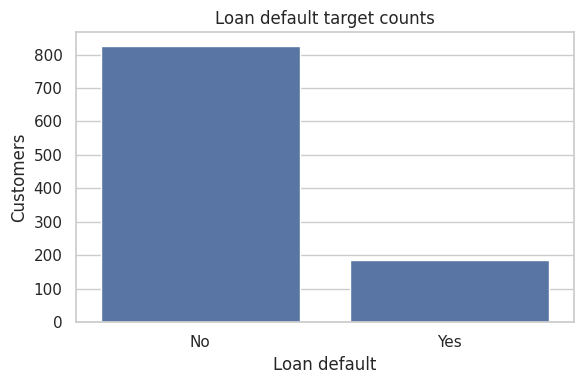

Target proportions:


,proportion
loan_default,
No,0.815217
Yes,0.184783


In [25]:
target = "loan_default"
if target not in df.columns:
    raise KeyError(f"Required target column {target!r} is missing. Found: {df.columns.tolist()}")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)
display(df[numeric_cols].describe().T if numeric_cols else pd.DataFrame())
for col in categorical_cols:
    print(f"\nValue counts for {col} (including missing):")
    display(df[col].value_counts(dropna=False).to_frame("count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target, order=df[target].value_counts().index)
plt.title("Loan default target counts")
plt.xlabel("Loan default")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()
print("Target proportions:")
display(df[target].value_counts(normalize=True, dropna=False).rename("proportion").to_frame())

In [26]:
print("Missing values before cleaning:")
missing_before = df.isnull().sum()
display(missing_before[missing_before > 0].to_frame("missing rows"))
print("Duplicate rows:", int(df.duplicated().sum()))

# Keep an audit of impossible numeric values for the written response.
for col in ["age", "income", "loan_amount", "credit_score", "employment_years", "existing_loans", "dependents", "bank_balance", "interest_rate", "previous_defaults"]:
    if col in df.columns and pd.api.types.is_numeric_dtype(df[col]):
        invalid = int((df[col] < 0).sum())
        if invalid:
            print(f"{col}: {invalid} negative value(s); inspect these records before deciding how to handle them.")

# Remove exact duplicate records. Do not silently modify questionable numeric observations.
df = df.drop_duplicates().copy()

# Fill categorical missing values with the most frequent value; use 'Unknown' if a column is entirely missing.
for col in df.select_dtypes(include=["object", "category", "bool"]).columns:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        fill_value = mode.iloc[0] if not mode.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)
        print(f"Filled missing {col!r} values with {fill_value!r}.")

# Numeric missing values are median-imputed later using a training-only pipeline to avoid leakage.
print("\nMissing values after duplicate removal and categorical fill (numeric values will be imputed in the model pipeline):")
display(df.isnull().sum()[df.isnull().sum() > 0].to_frame("remaining missing rows"))
print("Rows after duplicate removal:", len(df))

Missing values before cleaning:


,missing rows
education,61


Duplicate rows: 11
age: 5 negative value(s); inspect these records before deciding how to handle them.
income: 5 negative value(s); inspect these records before deciding how to handle them.
Filled missing 'education' values with 'Undergraduate'.

Missing values after duplicate removal and categorical fill (numeric values will be imputed in the model pipeline):


,remaining missing rows


Rows after duplicate removal: 1001


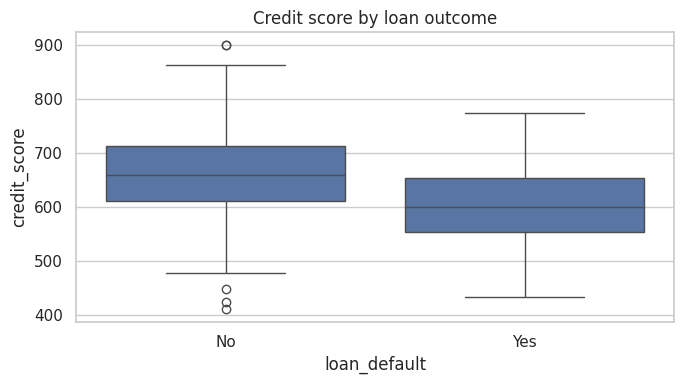

,default rate
city_tier,
Tier 2,0.194203
Tier 3,0.185185
Tier 1,0.174334


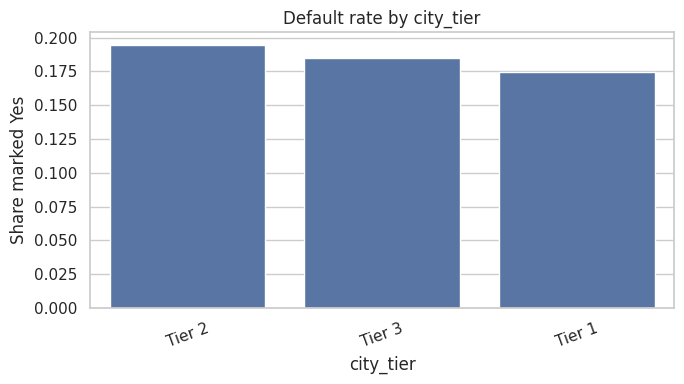

,default rate
employment_type,
Contract,0.237762
Self-employed,0.184332
Business,0.179348
Salaried,0.168490


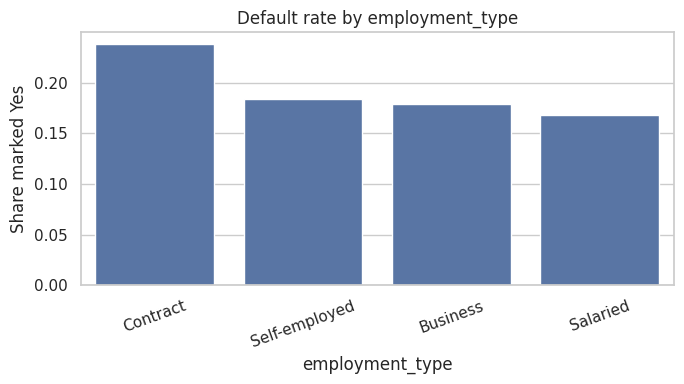

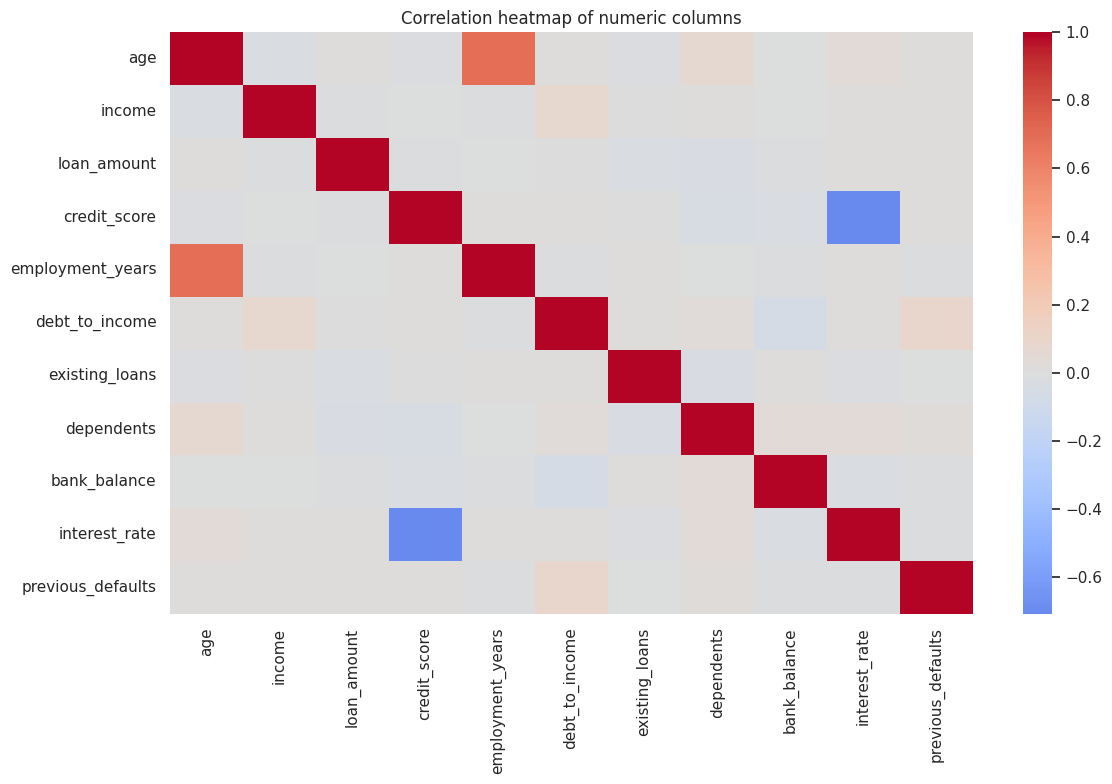

In [27]:
if "credit_score" not in df.columns:
    raise KeyError("Expected column 'credit_score' was not found.")
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target, y="credit_score")
plt.title("Credit score by loan outcome")
plt.tight_layout()
plt.show()

for col in ["city_tier", "employment_type"]:
    if col not in df.columns:
        raise KeyError(f"Expected column {col!r} was not found.")
    rates = df.groupby(col, observed=False)[target].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
    display(rates.rename("default rate").to_frame())
    plt.figure(figsize=(7, 4))
    sns.barplot(x=rates.index.astype(str), y=rates.values)
    plt.title(f"Default rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Share marked Yes")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

num_for_corr = df.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(num_for_corr.corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap of numeric columns")
plt.tight_layout()
plt.show()

In [28]:
# Preserve readable labels for plots, but create a modeling frame with the required target encoding.
if df[target].isna().any():
    raise ValueError("The target contains missing values. Resolve these rows before modeling.")
labels = set(df[target].astype(str).str.strip().unique())
if not labels.issubset({"Yes", "No"}):
    raise ValueError(f"Expected target labels Yes/No, found: {sorted(labels)}")
model_df = df.drop(columns=["customer_id"], errors="ignore").copy()
model_df[target] = model_df[target].astype(str).str.strip().map({"Yes": 1, "No": 0})
X_raw = model_df.drop(columns=[target])
y = model_df[target].astype(int)

# One-hot encode categories. Numeric missing values are handled downstream.
X = pd.get_dummies(X_raw, drop_first=True, dtype=int)
print("Feature matrix:", X.shape, "Target:", y.shape)
display(X.head())

Feature matrix: (1001, 24) Target: (1001,)


,age,income,loan_amount,credit_score,employment_years,debt_to_income,existing_loans,dependents,bank_balance,interest_rate,...,marital_status_Married,marital_status_Single,education_High School,education_Postgraduate,education_Undergraduate,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,city_tier_Tier 2,city_tier_Tier 3
0,59,52055.0,67855.0,589.0,8.1,0.436,0,4,1841.31,10.75,...,1,0,1,0,0,0,0,0,0,1
1,58,48605.0,187963.0,641.0,20.4,0.030,0,1,0.00,11.67,...,0,1,0,0,0,1,0,0,0,0
2,29,54590.0,244551.0,726.0,0.8,0.484,0,0,794.75,8.13,...,1,0,1,0,0,0,0,1,0,0
3,56,18951.0,561210.0,726.0,27.0,0.043,0,1,17515.85,8.63,...,0,1,1,0,0,1,0,0,0,0
4,37,76183.0,187744.0,658.0,10.1,0.412,1,3,10617.61,8.47,...,1,0,0,0,1,1,0,0,0,0


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Training features:", X_train.shape, "Training target:", y_train.shape)
print("Test features:", X_test.shape, "Test target:", y_test.shape)
print("Training target proportions:", y_train.value_counts(normalize=True).sort_index().to_dict())
print("Test target proportions:", y_test.value_counts(normalize=True).sort_index().to_dict())

Training features: (800, 24) Training target: (800,)
Test features: (201, 24) Test target: (201,)
Training target proportions: {0: 0.81625, 1: 0.18375}
Test target proportions: {0: 0.8159203980099502, 1: 0.18407960199004975}


In [30]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

# Imputation is learned from the training split only.
untuned_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeClassifier(random_state=42))
])
untuned_tree.fit(X_train, y_train)
train_accuracy = accuracy_score(y_train, untuned_tree.predict(X_train))
test_accuracy = accuracy_score(y_test, untuned_tree.predict(X_test))
print(f"Training accuracy: {train_accuracy:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")

Training accuracy: 1.000
Test accuracy: 0.761


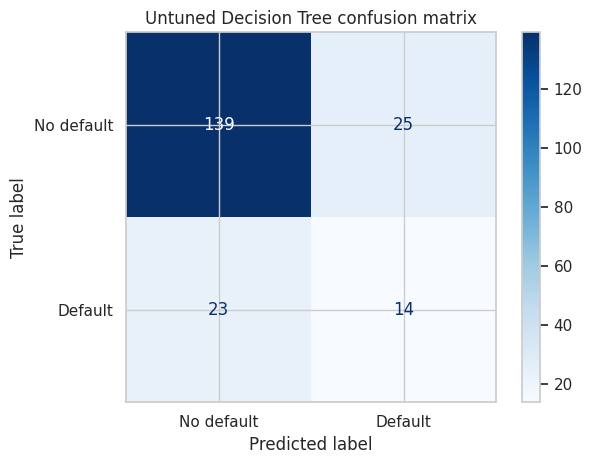

                precision    recall  f1-score   support

No default (0)       0.86      0.85      0.85       164
   Default (1)       0.36      0.38      0.37        37

      accuracy                           0.76       201
     macro avg       0.61      0.61      0.61       201
  weighted avg       0.77      0.76      0.76       201

ROC-AUC: 0.613


In [31]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score)

y_pred = untuned_tree.predict(X_test)
y_score = untuned_tree.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(cmap="Blues", values_format="d")
plt.title("Untuned Decision Tree confusion matrix")
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred, target_names=["No default (0)", "Default (1)"], zero_division=0))
print(f"ROC-AUC: {roc_auc_score(y_test, y_score):.3f}")

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Compare the requested depths on the same fixed split.
depth_rows = []
for depth in [3, 5, 7, 10]:
    pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("model", DecisionTreeClassifier(max_depth=depth, random_state=42))])
    pipe.fit(X_train, y_train)
    depth_rows.append({
        "max_depth": depth,
        "training_accuracy": accuracy_score(y_train, pipe.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, pipe.predict(X_test)),
    })
depth_results = pd.DataFrame(depth_rows)
display(depth_results)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    estimator=Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("model", DecisionTreeClassifier(random_state=42))]),
    param_grid={
        "model__max_depth": [3, 5, 7, 10, None],
        "model__min_samples_leaf": [1, 2, 5, 10],
        "model__criterion": ["gini", "entropy"],
    },
    scoring="f1", cv=cv, n_jobs=-1, refit=True
)
search.fit(X_train, y_train)
best = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best mean cross-validation F1:", round(search.best_score_, 3))
best_pred = best.predict(X_test)
best_score = best.predict_proba(X_test)[:, 1]
print("Tuned test accuracy:", round(accuracy_score(y_test, best_pred), 3))
print(classification_report(y_test, best_pred, target_names=["No default (0)", "Default (1)"], zero_division=0))
print("Tuned test ROC-AUC:", round(roc_auc_score(y_test, best_score), 3))

,max_depth,training_accuracy,test_accuracy
0,3,0.84375,0.820896
1,5,0.86875,0.825871
2,7,0.90500,0.805970
3,10,0.96250,0.800995


Best parameters: {'model__criterion': 'gini', 'model__max_depth': 7, 'model__min_samples_leaf': 10}
Best mean cross-validation F1: 0.31
Tuned test accuracy: 0.826
                precision    recall  f1-score   support

No default (0)       0.84      0.98      0.90       164
   Default (1)       0.60      0.16      0.26        37

      accuracy                           0.83       201
     macro avg       0.72      0.57      0.58       201
  weighted avg       0.79      0.83      0.78       201

Tuned test ROC-AUC: 0.697


In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

# Scale numeric features and one-hot encode categorical features within a pipeline.
num_features = X_raw.select_dtypes(include=np.number).columns.tolist()
cat_features = X_raw.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))]), cat_features),
], remainder="drop")
logistic = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=2000, random_state=42))])
logistic.fit(X_raw.loc[X_train.index], y_train)

# Compare all models at the default 0.5 classification threshold.
models = {"Logistic Regression": logistic, "Untuned Decision Tree": untuned_tree, "Tuned Decision Tree": best}
results = []
for name, model in models.items():
    features_test = X_raw.loc[X_test.index] if name == "Logistic Regression" else X_test
    pred = model.predict(features_test)
    score = model.predict_proba(features_test)[:, 1]
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Recall (default)": recall_score(y_test, pred, zero_division=0),
                    "F1 (default)": f1_score(y_test, pred, zero_division=0),
                    "ROC-AUC": roc_auc_score(y_test, score)})
comparison = pd.DataFrame(results).set_index("Model").round(3)
display(comparison)

,Accuracy,Recall (default),F1 (default),ROC-AUC
Model,,,,
Logistic Regression,0.836,0.270,0.377,0.765
Untuned Decision Tree,0.761,0.378,0.368,0.613
Tuned Decision Tree,0.826,0.162,0.255,0.697


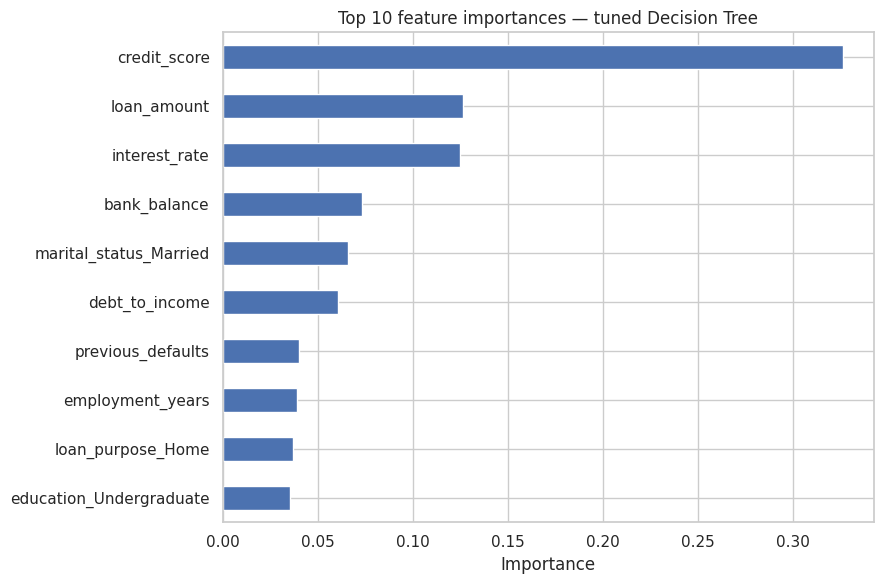

Top five features: ['credit_score', 'loan_amount', 'interest_rate', 'bank_balance', 'marital_status_Married']


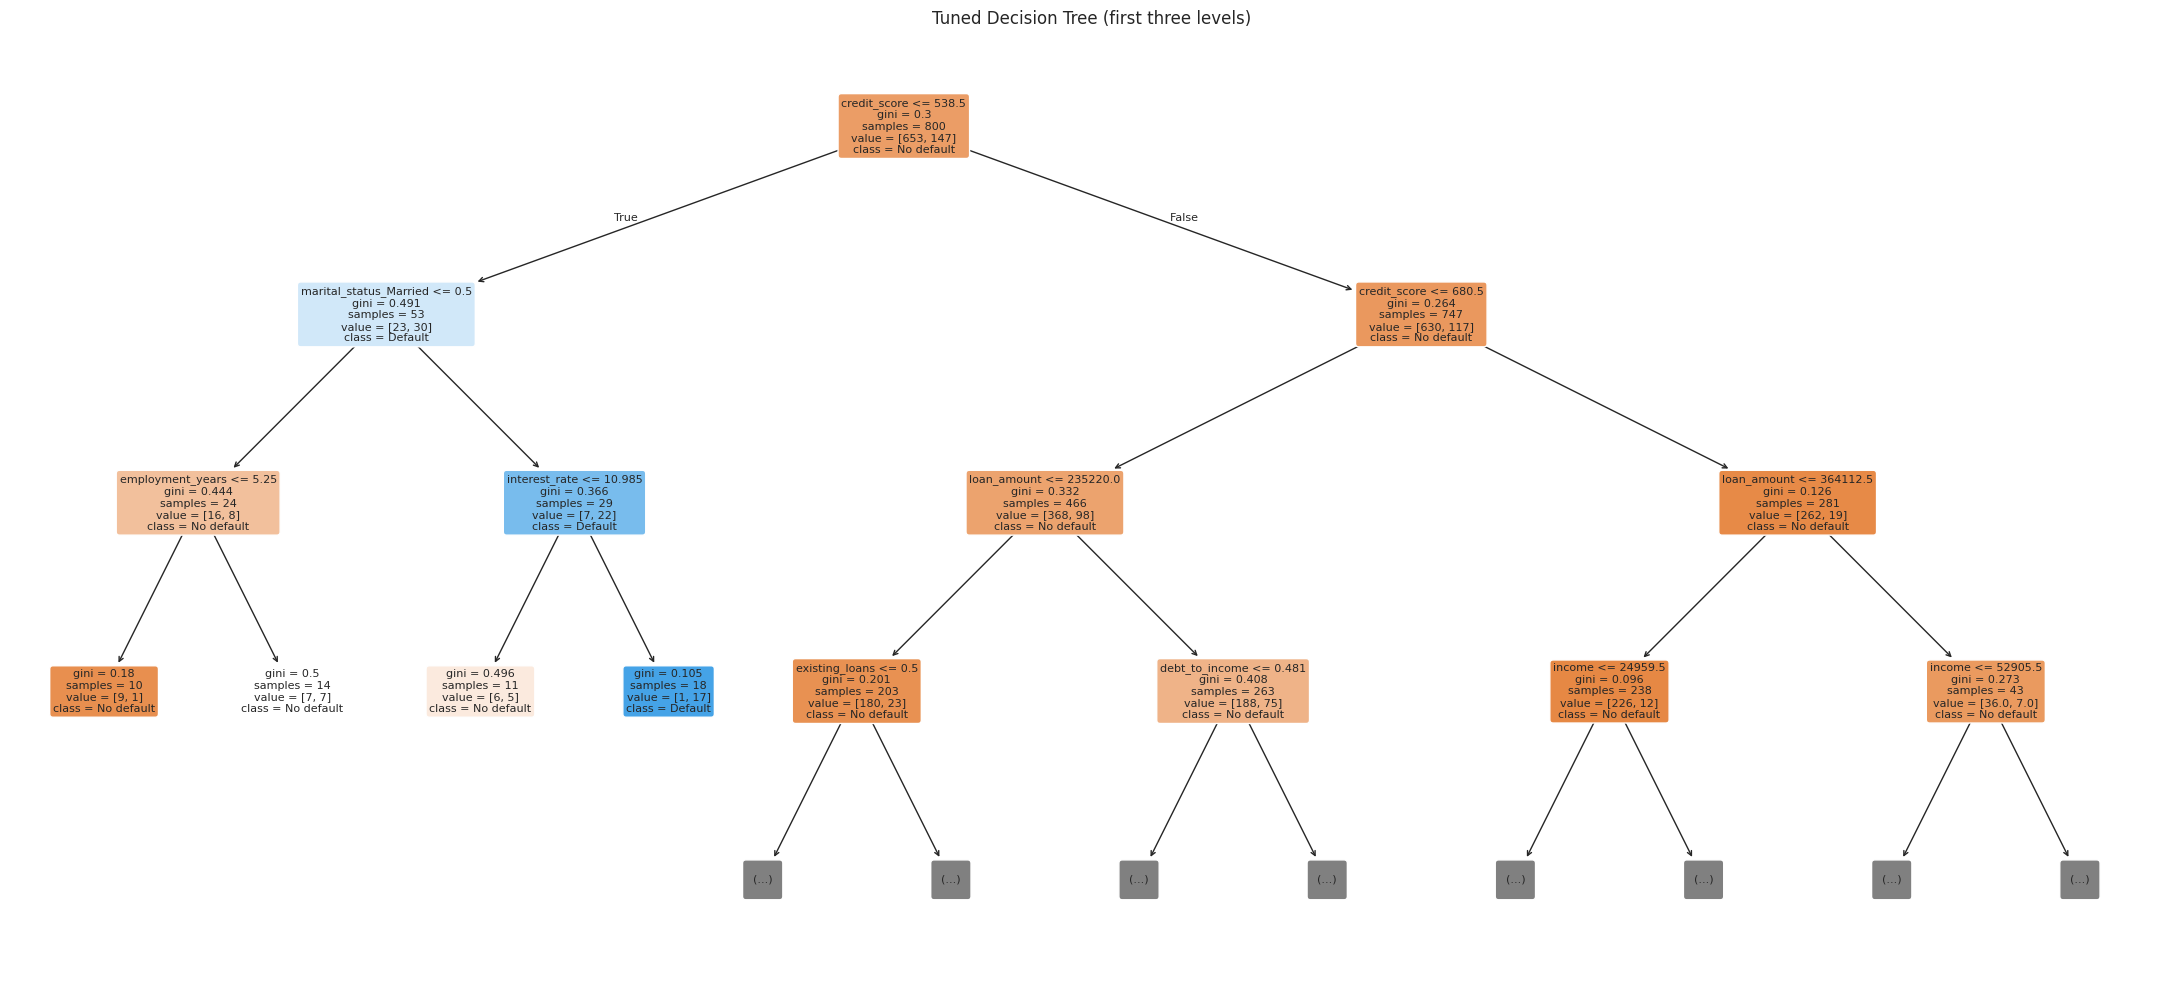

|--- credit_score <= 538.50
|   |--- marital_status_Married <= 0.50
|   |   |--- employment_years <= 5.25
|   |   |   |--- class: 0
|   |   |--- employment_years >  5.25
|   |   |   |--- class: 0
|   |--- marital_status_Married >  0.50
|   |   |--- interest_rate <= 10.99
|   |   |   |--- class: 0
|   |   |--- interest_rate >  10.99
|   |   |   |--- class: 1
|--- credit_score >  538.50
|   |--- credit_score <= 680.50
|   |   |--- loan_amount <= 235220.00
|   |   |   |--- existing_loans <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- existing_loans >  0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |--- loan_amount >  235220.00
|   |   |   |--- debt_to_income <= 0.48
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- debt_to_income >  0.48
|   |   |   |   |--- truncated branch of depth 4
|   |--- credit_score >  680.50
|   |   |--- loan_amount <= 364112.50
|   |   |   |--- income <= 24959.50
|   |   |   |   |--- truncated branch of d

In [34]:
from sklearn.tree import plot_tree, export_text

# The tuned model is a Pipeline; its fitted tree receives the one-hot feature columns.
tree_model = best.named_steps["model"]
importances = pd.Series(tree_model.feature_importances_, index=X.columns).nlargest(10).sort_values()
plt.figure(figsize=(9, 6))
importances.plot(kind="barh")
plt.title("Top 10 feature importances — tuned Decision Tree")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()
print("Top five features:", importances.nlargest(5).index.tolist())

plt.figure(figsize=(22, 10))
plot_tree(tree_model, feature_names=X.columns, class_names=["No default", "Default"],
          max_depth=3, filled=True, rounded=True, fontsize=8)
plt.title("Tuned Decision Tree (first three levels)")
plt.tight_layout()
plt.show()
print(export_text(tree_model, feature_names=list(X.columns), max_depth=3))